In [3]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from optimizers import GradientDescent, GDLineSearch, SGD, Momentum, AdaGrad, RMSprop, Adam

# 1. Chargement et prétraitement des données
def load_and_preprocess(filepath):
    df = pd.read_csv(filepath)
    
    if 'split' in df.columns:
        train_df = df[df['split'] == 'train']
        val_df = df[df['split'] == 'val']
        test_df = df[df['split'] == 'test']
    else:
        shuffled = df.sample(frac=1, random_state=42).reset_index(drop=True)
        n = len(shuffled)
        train_df = shuffled.iloc[:int(0.6*n)]
        val_df = shuffled.iloc[int(0.6*n):int(0.8*n)]
        test_df = shuffled.iloc[int(0.8*n):]

    y_train = train_df['y'].values
    y_val = val_df['y'].values
    y_test = test_df['y'].values
    
    X_train = train_df.drop(columns=['y', 'split'], errors='ignore').values
    X_val = val_df.drop(columns=['y', 'split'], errors='ignore').values
    X_test = test_df.drop(columns=['y', 'split'], errors='ignore').values
    
    # Standardisation sur le train uniquement
    mean = np.mean(X_train, axis=0)
    std = np.std(X_train, axis=0)
    std[std == 0] = 1.0
    
    X_train_scaled = (X_train - mean) / std
    X_val_scaled = (X_val - mean) / std
    X_test_scaled = (X_test - mean) / std
    
    # Ajout de la colonne de 1 pour le biais w0
    X_train_b = np.hstack([np.ones((X_train_scaled.shape[0], 1)), X_train_scaled])
    X_val_b = np.hstack([np.ones((X_val_scaled.shape[0], 1)), X_val_scaled])
    X_test_b = np.hstack([np.ones((X_test_scaled.shape[0], 1)), X_test_scaled])
    
    return X_train_b, y_train, X_val_b, y_val, X_test_b, y_test

# Test du chargement
X_tr, y_tr, X_v, y_v, X_te, y_te = load_and_preprocess("data/regression_nonlinear.csv")
print("Dimensions X_train avec biais :", X_tr.shape)
print("Dimensions y_train :", y_tr.shape)
   

Dimensions X_train avec biais : (216, 3)
Dimensions y_train : (216,)


In [6]:
# Fonction de coût Ridge (J_lambda) - Ne pénalise pas le biais w0
def compute_loss(w, X, y, lmbda=0.0):
    n = X.shape[0]
    error = X @ w - y
    P = np.eye(len(w))
    P[0, 0] = 0.0
    loss = (np.dot(error, error) / (2 * n)) + (lmbda / 2.0) * np.dot(w, P @ w)
    return loss

# Gradient analytique
def compute_gradient(w, X, y, lmbda=0.0):
    n = X.shape[0]
    error = X @ w - y
    P = np.eye(len(w))
    P[0, 0] = 0.0
    grad = (X.T @ error) / n + lmbda * (P @ w)
    return grad

# Vérification du gradient par différences finies centrales (h = 10^-5)
h = 1e-5
np.random.seed(42)
w_test = np.random.randn(X_tr.shape[1])
lmbda_test = 0.01

grad_analytique = compute_gradient(w_test, X_tr, y_tr, lmbda_test)
grad_numerique = np.zeros_like(w_test)

for i in range(len(w_test)):
    w_plus = w_test.copy()
    w_plus[i] += h
    w_moins = w_test.copy()
    w_moins[i] -= h
    grad_numerique[i] = (compute_loss(w_plus, X_tr, y_tr, lmbda_test) - compute_loss(w_moins, X_tr, y_tr, lmbda_test)) / (2 * h)

err_relative = np.linalg.norm(grad_analytique - grad_numerique) / (np.linalg.norm(grad_analytique) + np.linalg.norm(grad_numerique))
print(f"Erreur relative du gradient : {err_relative:.2e}")
if err_relative < 1e-6:
  print(".")
else:
    print(".")

Erreur relative du gradient : 8.34e-12
.


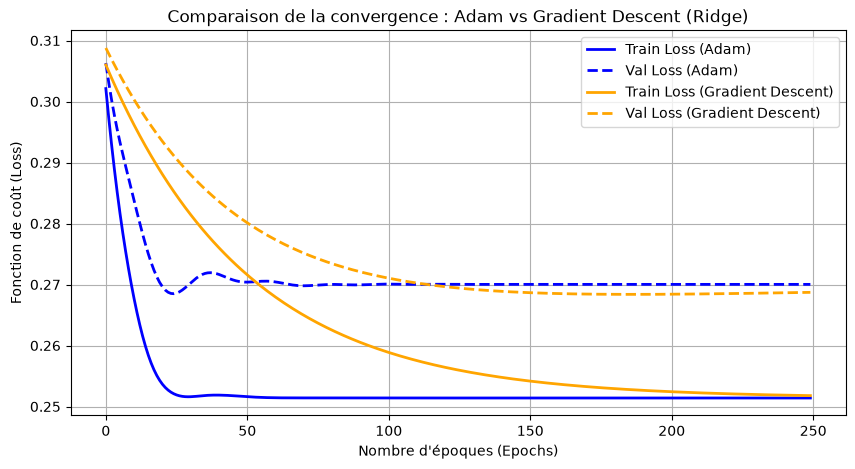

In [7]:
# 5. Fonction d'entraînement générique acceptant n'importe quel optimiseur
def train_model(X_train, y_train, X_val, y_val, optimizer, lmbda=0.01, epochs=300):
    np.random.seed(42)
    w = np.zeros(X_train.shape[1])
    
    train_losses = []
    val_losses = []
    
    for epoch in range(epochs):
        grad = compute_gradient(w, X_train, y_train, lmbda)
        w = optimizer.update(w, grad)
        
        # Enregistrement des pertes (Loss)
        train_losses.append(compute_loss(w, X_train, y_train, lmbda))
        val_losses.append(compute_loss(w, X_val, y_val, lmbda))
        
    return w, train_losses, val_losses

# Entraînement comparatif entre Adam et la Descente de Gradient classique
opt_adam = Adam(lr=0.01)
w_adam, loss_tr_adam, loss_val_adam = train_model(X_tr, y_tr, X_v, y_v, opt_adam, lmbda=0.01, epochs=250)

opt_gd = GradientDescent(lr=0.01)
w_gd, loss_tr_gd, loss_val_gd = train_model(X_tr, y_tr, X_v, y_v, opt_gd, lmbda=0.01, epochs=250)

# 6. Visualisation des courbes de convergence
plt.figure(figsize=(10, 5))
plt.plot(loss_tr_adam, label='Train Loss (Adam)', color='blue', lw=2)
plt.plot(loss_val_adam, label='Val Loss (Adam)', color='blue', linestyle='--', lw=2)
plt.plot(loss_tr_gd, label='Train Loss (Gradient Descent)', color='orange', lw=2)
plt.plot(loss_val_gd, label='Val Loss (Gradient Descent)', color='orange', linestyle='--', lw=2)

plt.xlabel("Nombre d'époques (Epochs)")
plt.ylabel("Fonction de coût (Loss)")
plt.title("Comparaison de la convergence : Adam vs Gradient Descent (Ridge)")
plt.legend()
plt.grid(True)
plt.show()